In [5]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set(style="white", context="talk")


In [5]:
from nilearn import datasets
# ── Config ──────────────────────────────────────────────────────────────
DATA_DIR = r"E:/fMRI dataset/LSD-PLACEBO"
OUTPUT_DIR = r'C:\Users\Leandre Sabourin\Music\Desktop\Projet VSCode\Psychedelic personnal project\cnn_connectivity_matrix\connectivity_matrices'
os.makedirs(OUTPUT_DIR, exist_ok=True)

SUBJECTS = sorted([s for s in os.listdir(DATA_DIR) if s.startswith('sub-')])
SESSIONS = ['ses-LSD', 'ses-PLCB']
RUNS = ['run-01', 'run-02', 'run-03']

print(f"Subjects: {SUBJECTS}")
print(f"Total subjects: {len(SUBJECTS)}")

# ── Atlas ────────────────────────────────────────────────────────────────
print("\nLoading atlas...")
atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7)
atlas_img = atlas.maps
labels = list(atlas.labels)
print(f"Atlas: {len(labels)} ROIs")
print(labels)

Subjects: ['sub-001', 'sub-002', 'sub-003', 'sub-004', 'sub-006', 'sub-009', 'sub-010', 'sub-011', 'sub-012', 'sub-013', 'sub-015', 'sub-017', 'sub-018', 'sub-019', 'sub-020']
Total subjects: 15

Loading atlas...


[fetch_atlas_schaefer_2018] Dataset found in C:\Users\Leandre Sabourin\nilearn_data\schaefer_2018

Atlas: 101 ROIs
['Background', '7Networks_LH_Vis_1', '7Networks_LH_Vis_2', '7Networks_LH_Vis_3', '7Networks_LH_Vis_4', '7Networks_LH_Vis_5', '7Networks_LH_Vis_6', '7Networks_LH_Vis_7', '7Networks_LH_Vis_8', '7Networks_LH_Vis_9', '7Networks_LH_SomMot_1', '7Networks_LH_SomMot_2', '7Networks_LH_SomMot_3', '7Networks_LH_SomMot_4', '7Networks_LH_SomMot_5', '7Networks_LH_SomMot_6', '7Networks_LH_DorsAttn_Post_1', '7Networks_LH_DorsAttn_Post_2', '7Networks_LH_DorsAttn_Post_3', '7Networks_LH_DorsAttn_Post_4', '7Networks_LH_DorsAttn_Post_5', '7Networks_LH_DorsAttn_Post_6', '7Networks_LH_DorsAttn_PrCv_1', '7Networks_LH_DorsAttn_FEF_1', '7Networks_LH_SalVentAttn_ParOper_1', '7Networks_LH_SalVentAttn_FrOperIns_1', '7Networks_LH_SalVentAttn_FrOperIns_2', '7Networks_LH_SalVentAttn_PFCl_1', '7Networks_LH_SalVentAttn_Med_1', '7Networks_LH_SalVentAttn_Med_2', '7Networks_LH_SalVentAttn_Med_3', '7Networks_LH_Limbic_OFC_1', '7Networks_LH_Limbic_TempPole_1', '7Networks_LH_Limbic_TempPole_2', '7Networks_LH_

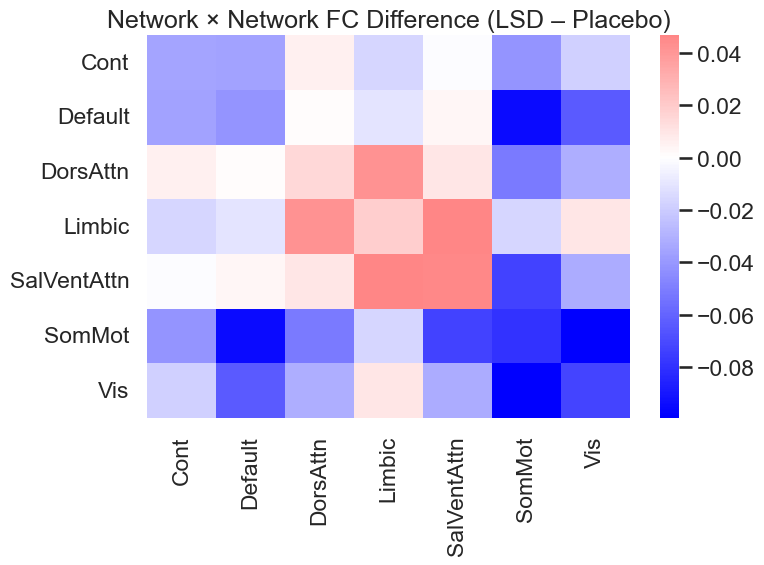

<Figure size 640x480 with 0 Axes>

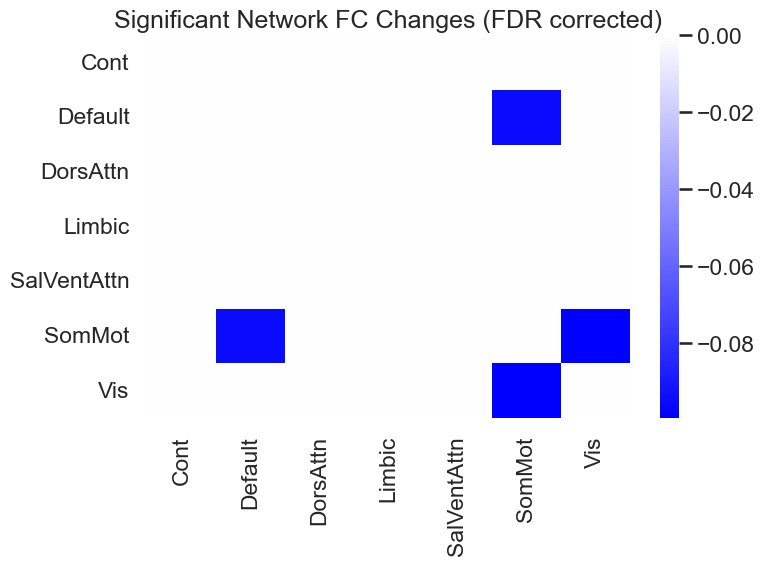

<Figure size 640x480 with 0 Axes>

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel

sns.set(style="white", context="talk")

# --- 1. Base directory ---
base_dir = r"C:\Users\Leandre Sabourin\Music\Desktop\Projet VSCode\deep-learning-LSD\time_series"

subjects = sorted([d for d in os.listdir(base_dir) if d.startswith("sub-")])
conditions = ["PLCB", "LSD"]

# --- 2. Load ROI labels (your list of 101 names) ---
roi_labels = np.array(['Background', '7Networks_LH_Vis_1', '7Networks_LH_Vis_2', '7Networks_LH_Vis_3', '7Networks_LH_Vis_4', '7Networks_LH_Vis_5', '7Networks_LH_Vis_6', '7Networks_LH_Vis_7', '7Networks_LH_Vis_8', '7Networks_LH_Vis_9', '7Networks_LH_SomMot_1', '7Networks_LH_SomMot_2', '7Networks_LH_SomMot_3', '7Networks_LH_SomMot_4', '7Networks_LH_SomMot_5', '7Networks_LH_SomMot_6', '7Networks_LH_DorsAttn_Post_1', '7Networks_LH_DorsAttn_Post_2', '7Networks_LH_DorsAttn_Post_3', '7Networks_LH_DorsAttn_Post_4', '7Networks_LH_DorsAttn_Post_5', '7Networks_LH_DorsAttn_Post_6', '7Networks_LH_DorsAttn_PrCv_1', '7Networks_LH_DorsAttn_FEF_1', '7Networks_LH_SalVentAttn_ParOper_1', '7Networks_LH_SalVentAttn_FrOperIns_1', '7Networks_LH_SalVentAttn_FrOperIns_2', '7Networks_LH_SalVentAttn_PFCl_1', '7Networks_LH_SalVentAttn_Med_1', '7Networks_LH_SalVentAttn_Med_2', '7Networks_LH_SalVentAttn_Med_3', '7Networks_LH_Limbic_OFC_1', '7Networks_LH_Limbic_TempPole_1', '7Networks_LH_Limbic_TempPole_2', '7Networks_LH_Cont_Par_1', '7Networks_LH_Cont_PFCl_1', '7Networks_LH_Cont_pCun_1', '7Networks_LH_Cont_Cing_1', '7Networks_LH_Default_Temp_1', '7Networks_LH_Default_Temp_2', '7Networks_LH_Default_Par_1', '7Networks_LH_Default_Par_2', '7Networks_LH_Default_PFC_1', '7Networks_LH_Default_PFC_2', '7Networks_LH_Default_PFC_3', '7Networks_LH_Default_PFC_4', '7Networks_LH_Default_PFC_5', '7Networks_LH_Default_PFC_6', '7Networks_LH_Default_PFC_7', '7Networks_LH_Default_pCunPCC_1', '7Networks_LH_Default_pCunPCC_2', '7Networks_RH_Vis_1', '7Networks_RH_Vis_2', '7Networks_RH_Vis_3', '7Networks_RH_Vis_4', '7Networks_RH_Vis_5', '7Networks_RH_Vis_6', '7Networks_RH_Vis_7', '7Networks_RH_Vis_8', '7Networks_RH_SomMot_1', '7Networks_RH_SomMot_2', '7Networks_RH_SomMot_3', '7Networks_RH_SomMot_4', '7Networks_RH_SomMot_5', '7Networks_RH_SomMot_6', '7Networks_RH_SomMot_7', '7Networks_RH_SomMot_8', '7Networks_RH_DorsAttn_Post_1', '7Networks_RH_DorsAttn_Post_2', '7Networks_RH_DorsAttn_Post_3', '7Networks_RH_DorsAttn_Post_4', '7Networks_RH_DorsAttn_Post_5', '7Networks_RH_DorsAttn_PrCv_1', '7Networks_RH_DorsAttn_FEF_1', '7Networks_RH_SalVentAttn_TempOccPar_1', '7Networks_RH_SalVentAttn_TempOccPar_2', '7Networks_RH_SalVentAttn_FrOperIns_1', '7Networks_RH_SalVentAttn_Med_1', '7Networks_RH_SalVentAttn_Med_2', '7Networks_RH_Limbic_OFC_1', '7Networks_RH_Limbic_TempPole_1', '7Networks_RH_Cont_Par_1', '7Networks_RH_Cont_Par_2', '7Networks_RH_Cont_PFCl_1', '7Networks_RH_Cont_PFCl_2', '7Networks_RH_Cont_PFCl_3', '7Networks_RH_Cont_PFCl_4', '7Networks_RH_Cont_Cing_1', '7Networks_RH_Cont_PFCmp_1', '7Networks_RH_Cont_pCun_1', '7Networks_RH_Default_Par_1', '7Networks_RH_Default_Temp_1', '7Networks_RH_Default_Temp_2', '7Networks_RH_Default_Temp_3', '7Networks_RH_Default_PFCv_1', '7Networks_RH_Default_PFCv_2', '7Networks_RH_Default_PFCdPFCm_1', '7Networks_RH_Default_PFCdPFCm_2', '7Networks_RH_Default_PFCdPFCm_3', '7Networks_RH_Default_pCunPCC_1', '7Networks_RH_Default_pCunPCC_2'])

# --- 3. Extract network names ---
def extract_network(label):
    if label == "Background":
        return "Background"
    return label.split("_")[2]  # e.g. "Vis", "SomMot", "Default"

region_to_network = np.array([extract_network(lbl) for lbl in roi_labels])
networks = np.unique(region_to_network)
networks = [n for n in networks if n != "Background"]  # remove background

# --- 4. Load time series & compute FC ---
fc = {sub: {} for sub in subjects}

for sub in subjects:
    for cond in conditions:
        path = os.path.join(base_dir, sub, cond, "time_series.npy")
        ts = np.load(path)  # shape: (timepoints, n_ROIs)
        fc_mat = np.corrcoef(ts.T)
        fc[sub][cond] = fc_mat

n_subj = len(subjects)
n_regions = fc[subjects[0]]["PLCB"].shape[0]

# --- 5. Fisher-z transform ---
def fisher_z(r):
    r = np.clip(r, -0.999999, 0.999999)
    return 0.5 * np.log((1 + r) / (1 - r))

z_plcb = np.stack([fisher_z(fc[sub]["PLCB"]) for sub in subjects])
z_lsd  = np.stack([fisher_z(fc[sub]["LSD"])  for sub in subjects])

# --- 6. Compute network-level FC ---
def network_fc(z_mat, region_to_network, networks):
    n_net = len(networks)
    net_mat = np.zeros((n_net, n_net))
    
    for i, net_i in enumerate(networks):
        idx_i = np.where(region_to_network == net_i)[0]
        for j, net_j in enumerate(networks):
            idx_j = np.where(region_to_network == net_j)[0]
            submat = z_mat[np.ix_(idx_i, idx_j)]
            net_mat[i, j] = np.mean(submat)
    return net_mat

net_plcb = np.stack([network_fc(z_plcb[s], region_to_network, networks) for s in range(n_subj)])
net_lsd  = np.stack([network_fc(z_lsd[s],  region_to_network, networks) for s in range(n_subj)])

# --- 7. LSD – PLCB differences ---
delta_net = net_lsd - net_plcb
mean_delta_net = delta_net.mean(axis=0)

# --- 8. Paired t-tests ---
t_vals = np.zeros_like(mean_delta_net)
p_vals = np.zeros_like(mean_delta_net)

for i in range(len(networks)):
    for j in range(len(networks)):
        t, p = ttest_rel(net_lsd[:, i, j], net_plcb[:, i, j])
        t_vals[i, j] = t
        p_vals[i, j] = p

# --- 9. FDR correction ---
def fdr_bh(pvals, alpha=0.05):
    p = pvals.flatten()
    n = p.size
    idx = np.argsort(p)
    p_sorted = p[idx]
    thresh = alpha * np.arange(1, n+1) / n
    below = p_sorted <= thresh
    if not np.any(below):
        return np.zeros_like(pvals, dtype=bool)
    k = np.max(np.where(below))
    cutoff = p_sorted[k]
    return (pvals <= cutoff)

sig_mask = fdr_bh(p_vals)

# --- 10. Visualizations ---
plt.figure(figsize=(8, 6))
sns.heatmap(mean_delta_net, xticklabels=networks, yticklabels=networks,
            cmap="bwr", center=0)
plt.title("Network × Network FC Difference (LSD – Placebo)")
plt.tight_layout()
plt.show()
plt.savefig("FC difference.png")

plt.figure(figsize=(8, 6))
sns.heatmap(np.where(sig_mask, mean_delta_net, 0),
            xticklabels=networks, yticklabels=networks,
            cmap="bwr", center=0)
plt.title("Significant Network FC Changes (FDR corrected)")
plt.tight_layout()
plt.show()
plt.savefig("FC changes with FDR corrections.png")   